# SafeSathi — Motion Event Classifier

Trains the classifier that scores a short window of phone accelerometer +
gyroscope readings as one of: `normal`, `running`, `phone_snatch`,
`violent_movement`, `sudden_fall`. This is the exact model
`app/services/motion_classifier_service.py` loads at startup.

**Pipeline:** generate → save to CSV → load from CSV → clean → explore →
train → evaluate → save `.pkl`. The save/reload step is deliberate, not
decorative — it's what makes this notebook (not the in-memory arrays
inside it) the actual source of truth for what the model was trained on.
`data/motion_training_data.csv` is the dataset this project trains on,
committed to the repo like any other training data would be.

## Why synthetic data, stated plainly

No labeled real-world dataset of phone-snatch / violent-movement /
sudden-fall accelerometer recordings exists to train on — collecting one
honestly means staging assaults, which is its own ethics-board research
project, well outside this one. Each class below is instead generated
from a **documented, physically-reasoned distribution** grounded in how
that event actually moves a phone — not numbers picked to flatter the
model. The reasoning sits next to each class's parameters, so every
number here can be defended, not just quoted.


In [1]:
import json
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score, train_test_split

sns.set_theme(style="whitegrid")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "app").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACTS_DIR = PROJECT_ROOT / "app" / "ml_artifacts"
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)


## 1. Configuration

Feature order and class labels are fixed and must match what
`motion_classifier_service.py` sends at inference time — this list is the
contract between training and serving.


In [2]:
SAMPLES_PER_CLASS = 600

FEATURE_NAMES = [
    "accel_mean", "accel_peak", "accel_variance", "accel_peak_to_mean",
    "gyro_mean", "gyro_peak", "gyro_variance", "gyro_peak_to_mean",
]
CLASS_LABELS = ["normal", "running", "phone_snatch", "violent_movement", "sudden_fall"]


## 2. Per-class distributions — and the reasoning behind each

Units: accelerometer magnitude in **m/s²**, gyroscope magnitude in
**rad/s** (matching `SensorLog.model.ts` on the backend and the mobile
app's `useMotionDetector` hook).

| Class | Reasoning |
|---|---|
| `normal` | Near-gravity magnitude (~9.8 m/s²), low variance, low gyro — a phone at rest or carried steadily. |
| `running` | Elevated mean + periodic variance from footstrike; moderate gyro from natural arm swing. |
| `phone_snatch` | A short, very sharp acceleration **and** rotation spike — high peak, high gyro peak (the twist as it's grabbed) — but mean isn't pulled down, since there's no free-fall phase. |
| `violent_movement` (struggling) | Sustained high variance and moderately high peak on both sensors — continuous chaotic motion, not one clean spike. |
| `sudden_fall` | Very high peak (the impact) but a **lower** mean than the sustained-high classes — part of the window is a near-free-fall dip before impact. That peak-high / mean-low combination is the fall signature, not peak alone. |


In [3]:
@dataclass
class ClassProfile:
    accel_mean: tuple
    accel_peak: tuple
    accel_variance: tuple
    gyro_mean: tuple
    gyro_peak: tuple
    gyro_variance: tuple


CLASS_PROFILES = {
    "normal": ClassProfile((9.8, 0.6), (11.5, 1.2), (0.8, 0.4), (0.15, 0.08), (0.4, 0.15), (0.05, 0.03)),
    "running": ClassProfile((13.0, 1.5), (18.0, 2.5), (3.0, 1.0), (0.5, 0.15), (1.0, 0.3), (0.25, 0.1)),
    "phone_snatch": ClassProfile((12.0, 2.0), (32.0, 5.0), (6.0, 2.0), (1.2, 0.4), (6.5, 1.5), (2.5, 0.8)),
    "violent_movement": ClassProfile((14.0, 2.5), (24.0, 4.0), (7.0, 2.0), (1.8, 0.5), (3.5, 1.0), (1.8, 0.6)),
    "sudden_fall": ClassProfile((6.5, 1.8), (28.0, 5.0), (8.0, 2.5), (0.8, 0.3), (2.5, 0.8), (1.0, 0.4)),
}


## 3. Generate readings and save to CSV — this is the "data collection" step

In [4]:
def _sample_positive(rng, mean_std):
    mean, std = mean_std
    return float(max(0.0, rng.normal(mean, std)))


def generate_readings(samples_per_class: int, seed: int) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    rows = []
    for label in CLASS_LABELS:
        profile = CLASS_PROFILES[label]
        for _ in range(samples_per_class):
            accel_mean = _sample_positive(rng, profile.accel_mean)
            accel_peak = max(accel_mean, _sample_positive(rng, profile.accel_peak))
            gyro_mean = _sample_positive(rng, profile.gyro_mean)
            gyro_peak = max(gyro_mean, _sample_positive(rng, profile.gyro_peak))
            rows.append({
                "accel_mean": accel_mean,
                "accel_peak": accel_peak,
                "accel_variance": _sample_positive(rng, profile.accel_variance),
                "gyro_mean": gyro_mean,
                "gyro_peak": gyro_peak,
                "gyro_variance": _sample_positive(rng, profile.gyro_variance),
                "label": label,
            })
    return pd.DataFrame(rows)


raw_df = generate_readings(SAMPLES_PER_CLASS, RANDOM_SEED)

csv_path = DATA_DIR / "motion_training_data.csv"
raw_df.to_csv(csv_path, index=False)
print(f"Saved {len(raw_df)} rows to {csv_path}")


Saved 3000 rows to /home/claude/safesathi/SafeSathi/ai-services/data/motion_training_data.csv


## 4. Load the dataset from disk

This is the step that matters for reproducibility: from here on, the
notebook works from the **file on disk**, the same way it would if this
were real sensor logs collected from the app instead of generated above.
Re-running training later means re-running from here, not from section 3.


In [5]:
df = pd.read_csv(csv_path)
print(f"Loaded {df.shape[0]} rows, {df.shape[1]} columns from {csv_path}")
df.head()


Loaded 3000 rows, 7 columns from /home/claude/safesathi/SafeSathi/ai-services/data/motion_training_data.csv


,accel_mean,accel_peak,accel_variance,gyro_mean,gyro_peak,gyro_variance,label
0,9.982830,10.252019,0.019586,0.210036,0.541085,0.010935,normal
1,9.876704,11.120509,1.151759,0.148656,0.272043,0.073334,normal
2,9.839618,12.852689,0.947500,0.187401,0.271106,0.021234,normal
3,10.327070,11.440089,1.289017,0.135211,0.297861,0.045364,normal
4,9.543003,11.077440,0.965093,0.192585,0.454817,0.062925,normal


## 5. Clean the data

In [6]:
print("Missing values per column:")
print(df.isnull().sum())

duplicate_count = df.duplicated().sum()
print(f"\nExact duplicate rows: {duplicate_count}")

print("\nClass balance:")
print(df["label"].value_counts())

# Physically impossible readings (negative magnitude) would indicate a
# sensor/pipeline bug upstream — checked here even though none are
# expected from generation above, because this check is what would catch
# it in real collected data too.
negative_counts = (df[["accel_mean", "accel_peak", "accel_variance", "gyro_mean", "gyro_peak", "gyro_variance"]] < 0).sum()
print(f"\nNegative-value cells (should be 0): {negative_counts.sum()}")

df = df.drop_duplicates().dropna()
print(f"\nRows after cleaning: {len(df)}")


Missing values per column:
accel_mean        0
accel_peak        0
accel_variance    0
gyro_mean         0
gyro_peak         0
gyro_variance     0
label             0
dtype: int64

Exact duplicate rows: 0

Class balance:
label
normal              600
running             600
phone_snatch        600
violent_movement    600
sudden_fall         600
Name: count, dtype: int64

Negative-value cells (should be 0): 0

Rows after cleaning: 3000


## 6. Feature engineering

In [7]:
df["accel_peak_to_mean"] = df["accel_peak"] / df["accel_mean"].replace(0, np.nan)
df["gyro_peak_to_mean"] = df["gyro_peak"] / df["gyro_mean"].replace(0, np.nan)
df = df.fillna(0.0)

df[FEATURE_NAMES + ["label"]].head()


,accel_mean,accel_peak,accel_variance,accel_peak_to_mean,gyro_mean,gyro_peak,gyro_variance,gyro_peak_to_mean,label
0,9.982830,10.252019,0.019586,1.026965,0.210036,0.541085,0.010935,2.576151,normal
1,9.876704,11.120509,1.151759,1.125933,0.148656,0.272043,0.073334,1.830021,normal
2,9.839618,12.852689,0.947500,1.306218,0.187401,0.271106,0.021234,1.446665,normal
3,10.327070,11.440089,1.289017,1.107777,0.135211,0.297861,0.045364,2.202931,normal
4,9.543003,11.077440,0.965093,1.160792,0.192585,0.454817,0.062925,2.361644,normal


### EDA — do the classes actually look separable?

In [8]:
df.groupby("label")[FEATURE_NAMES].mean().loc[CLASS_LABELS]


,accel_mean,accel_peak,accel_variance,accel_peak_to_mean,gyro_mean,gyro_peak,gyro_variance,gyro_peak_to_mean
label,,,,,,,,
normal,9.777123,11.533609,0.809527,1.183412,0.148112,0.408539,0.049779,9.597998
running,13.093344,17.972785,3.016764,1.386931,0.499327,1.016409,0.250362,2.357274
phone_snatch,11.985132,31.868237,6.007617,2.745857,1.161738,6.489665,2.467379,6.596333
violent_movement,13.808762,24.025578,7.086683,1.800546,1.761219,3.585100,1.792466,2.214612
sudden_fall,6.572901,28.611583,7.926145,4.765581,0.815396,2.545788,1.000161,4.094080


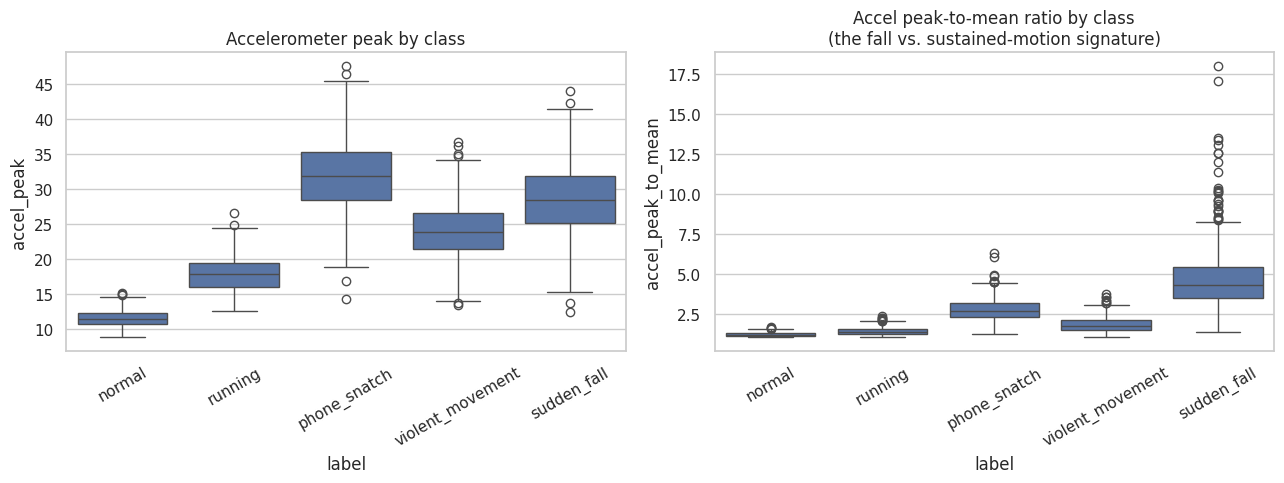

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="label", y="accel_peak", order=CLASS_LABELS, ax=axes[0])
axes[0].set_title("Accelerometer peak by class")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=df, x="label", y="accel_peak_to_mean", order=CLASS_LABELS, ax=axes[1])
axes[1].set_title("Accel peak-to-mean ratio by class\n(the fall vs. sustained-motion signature)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


`sudden_fall` should visibly separate from `phone_snatch` /
`violent_movement` here even though all three have high peaks — the
peak-to-mean ratio is what tells them apart, matching section 2.

## 7. Train / test split


In [10]:
X = df[FEATURE_NAMES].to_numpy()
y = df["label"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(f"Train: {X_train.shape[0]} samples · Test: {X_test.shape[0]} samples")


Train: 2400 samples · Test: 600 samples


## 8. Train

A `RandomForestClassifier` — it handles the non-linear peak/mean
interactions each class profile relies on, and its `feature_importances_`
gives a directly inspectable explanation of *why* it makes a given call.


In [11]:
clf = RandomForestClassifier(
    n_estimators=200, max_depth=8, min_samples_leaf=5,
    random_state=RANDOM_SEED, class_weight="balanced",
)
clf.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

## 9. Evaluate

In [12]:
y_pred = clf.predict(X_test)
report = classification_report(y_test, y_pred, output_dict=True)
print(classification_report(y_test, y_pred))


                  precision    recall  f1-score   support

          normal       1.00      1.00      1.00       120
    phone_snatch       0.95      0.93      0.94       120
         running       1.00      0.98      0.99       120
     sudden_fall       0.94      0.96      0.95       120
violent_movement       0.91      0.93      0.92       120

        accuracy                           0.96       600
       macro avg       0.96      0.96      0.96       600
    weighted avg       0.96      0.96      0.96       600



In [13]:
cv_scores = cross_val_score(clf, X, y, cv=5)
print(f"5-fold CV accuracy: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")


5-fold CV accuracy: 0.9707 +/- 0.0023


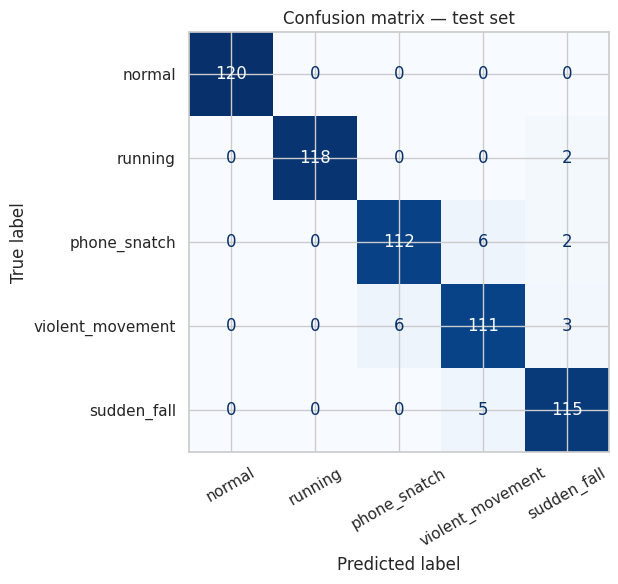

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=CLASS_LABELS)
fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASS_LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
plt.xticks(rotation=30)
plt.title("Confusion matrix — test set")
plt.tight_layout()
plt.show()


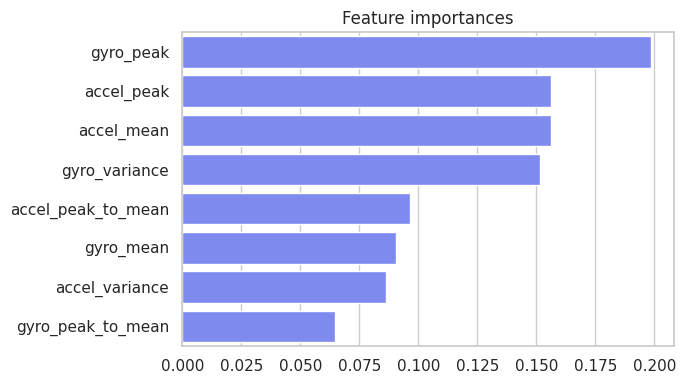

  gyro_peak: 0.1984
  accel_peak: 0.1563
  accel_mean: 0.1562
  gyro_variance: 0.1517
  accel_peak_to_mean: 0.0965
  gyro_mean: 0.0904
  accel_variance: 0.0861
  gyro_peak_to_mean: 0.0645


In [15]:
importances = sorted(zip(FEATURE_NAMES, clf.feature_importances_), key=lambda p: -p[1])
fig, ax = plt.subplots(figsize=(7, 4))
names, values = zip(*importances)
sns.barplot(x=list(values), y=list(names), ax=ax, color="#6C7BFF")
ax.set_title("Feature importances")
plt.tight_layout()
plt.show()
for name, importance in importances:
    print(f"  {name}: {importance:.4f}")


## 10. Save the model as `.pkl`

`app/core/settings.py` → `motion_classifier_path` points at this exact
file. Re-running this notebook top-to-bottom *is* the retraining
workflow.


In [16]:
import joblib  # joblib.dump uses the pickle protocol under the hood —
                # this .pkl is a genuine pickle file, joblib is just the
                # scikit-learn-recommended way to write one for a model
                # containing large numpy arrays.

model_path = ARTIFACTS_DIR / "motion_classifier.pkl"
joblib.dump(clf, model_path)

metadata = {
    "feature_names": FEATURE_NAMES,
    "class_labels": CLASS_LABELS,
    "trained_on": str(csv_path.relative_to(PROJECT_ROOT)),
    "samples_per_class": SAMPLES_PER_CLASS,
    "test_accuracy": report["accuracy"],
    "cv_accuracy_mean": float(cv_scores.mean()),
    "cv_accuracy_std": float(cv_scores.std()),
    "per_class_f1": {label: report[label]["f1-score"] for label in CLASS_LABELS},
}
metadata_path = ARTIFACTS_DIR / "motion_classifier_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2))

print(f"Saved model to    {model_path}")
print(f"Saved metadata to {metadata_path}")


Saved model to    /home/claude/safesathi/SafeSathi/ai-services/app/ml_artifacts/motion_classifier.pkl
Saved metadata to /home/claude/safesathi/SafeSathi/ai-services/app/ml_artifacts/motion_classifier_metadata.json


## 11. How this connects to the rest of SafeSathi

- `app/services/motion_classifier_service.py` loads this `.pkl` at
  startup and uses it to score every sensor window the mobile app
  uploads via `POST /internal/motion/classify`.
- `data/motion_training_data.csv` and `app/ml_artifacts/` are both
  **committed to git** — after re-running this notebook,
  `git add data app/ml_artifacts && git commit && git push` is the whole
  deployment step. Render redeploys and picks up the new model.
- `GET /health` on the AI microservice won't show a model version, but a
  successful load without falling back to the threshold classifier is
  confirmed by the `motion_classifier_loaded` field there.
